# 00 · Exploración guiada (Hito 1)
**Proyecto semestral · Sala de crisis COVID-19 · Gestión de Datos IN1232C · 2026-2**

Punto de partida del proyecto: conocer los reportes diarios de Johns Hopkins (JHU CSSE) entre el **22-ene-2020 y el 30-jun-2020**.

| # | Lo que pide el enunciado | Sección |
|---|---|---|
| 1 | Cargar `01-22-2020.csv`: primeras filas, filas/columnas, tipos | §2 |
| 2 | Nulos por columna y qué significan | §3 |
| 3 | Nombres en snake_case y fecha de actualización AAAA-MM-DD | §4 |
| 4 | Unir ene–jun 2020 en un DataFrame (dos cambios de esquema) | §5 |
| 5 | Top 10 países al 30-jun-2020 y evolución de Chile | §6 |
| 6 | Perfilado automático (ydata-profiling) + 3 observaciones | §7 |

> Los datos crudos **no** se suben al repositorio: este notebook los descarga desde GitHub (URLs *raw*).

## 1 · Configuración

In [1]:
import os, re, sys
from pathlib import Path
import requests
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

URL_BASE = ('https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/'
            'csse_covid_19_data/csse_covid_19_daily_reports/')
EN_COLAB = 'google.colab' in sys.modules
# Raíz del proyecto: en Colab, el disco de la sesión; localmente, la raíz del repositorio
PROYECTO = Path('/content') if EN_COLAB else (Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
RAW_DIR = PROYECTO / 'data' / 'raw' / 'daily_reports'   # capa CRUDA: los CSV tal cual (no se versiona en git)
RAW_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR = PROYECTO / 'reports'; REPORTS_DIR.mkdir(exist_ok=True)

FECHA_INI, FECHA_FIN = '2020-01-22', '2020-06-30'

In [2]:
def descargar_reporte(fecha: pd.Timestamp) -> Path:
    """Descarga el reporte diario de una fecha (si no existe ya en disco) y devuelve su ruta."""
    nombre = fecha.strftime('%m-%d-%Y') + '.csv'          # los archivos de JHU se llaman MM-DD-YYYY.csv
    ruta = RAW_DIR / nombre
    if not ruta.exists():
        r = requests.get(URL_BASE + nombre, timeout=60)
        r.raise_for_status()
        ruta.write_bytes(r.content)
    return ruta

fechas = pd.date_range(FECHA_INI, FECHA_FIN, freq='D')
rutas = [descargar_reporte(f) for f in fechas]
print(f'{len(rutas)} reportes diarios disponibles en {RAW_DIR}')

161 reportes diarios disponibles en /home/claude/facuna-m/proyecto-gestion-datos-2026/data/raw/daily_reports


## 2 · El primer reporte: 22-ene-2020

In [3]:
df0 = pd.read_csv(RAW_DIR / '01-22-2020.csv')
df0.head(10)

,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered
0,Anhui,Mainland China,1/22/2020 17:00,1.0,NaN,NaN
1,Beijing,Mainland China,1/22/2020 17:00,14.0,NaN,NaN
2,Chongqing,Mainland China,1/22/2020 17:00,6.0,NaN,NaN
3,Fujian,Mainland China,1/22/2020 17:00,1.0,NaN,NaN
4,Gansu,Mainland China,1/22/2020 17:00,NaN,NaN,NaN
5,Guangdong,Mainland China,1/22/2020 17:00,26.0,NaN,NaN
6,Guangxi,Mainland China,1/22/2020 17:00,2.0,NaN,NaN
7,Guizhou,Mainland China,1/22/2020 17:00,1.0,NaN,NaN
8,Hainan,Mainland China,1/22/2020 17:00,4.0,NaN,NaN
9,Hebei,Mainland China,1/22/2020 17:00,1.0,NaN,NaN


In [4]:
print('Filas, columnas:', df0.shape)
df0.info()

Filas, columnas: (76, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76 entries, 0 to 75
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Province/State  64 non-null     object 
 1   Country/Region  76 non-null     object 
 2   Last Update     76 non-null     object 
 3   Confirmed       66 non-null     float64
 4   Deaths          39 non-null     float64
 5   Recovered       39 non-null     float64
dtypes: float64(3), object(3)
memory usage: 3.7+ KB


**Lectura:** el primer día trae **76 filas y 6 columnas**. Solo 31 son provincias de China (que aquí aparece como *Mainland China*); el resto incluye 17 estados de Malasia y 8 territorios del Reino Unido con valores en 0 o vacíos, que JHU **agregó después** a este archivo antiguo (ediciones retroactivas). `Confirmed`, `Deaths` y `Recovered` se leen como `float64` y no como enteros: es la señal de que tienen valores vacíos (en pandas un entero clásico no admite `NaN`). `Last Update` se lee como texto (`object`), no como fecha.

## 3 · Valores nulos y su significado

In [5]:
nulos = pd.DataFrame({'nulos': df0.isna().sum(), '%': (df0.isna().mean() * 100).round(1)})
nulos

,nulos,%
Province/State,12,15.8
Country/Region,0,0.0
Last Update,0,0.0
Confirmed,10,13.2
Deaths,37,48.7
Recovered,37,48.7


In [6]:
# ¿Quiénes tienen Province/State vacío? -> países que reportan a nivel nacional
df0[df0['Province/State'].isna()]

,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered
35,NaN,Japan,1/22/2020 17:00,2.0,NaN,NaN
36,NaN,Thailand,1/22/2020 17:00,4.0,0.0,2.0
37,NaN,South Korea,1/22/2020 17:00,1.0,NaN,NaN
39,NaN,Kiribati,1/22/2020 17:00,0.0,0.0,0.0
40,NaN,Palau,1/22/2020 17:00,0.0,0.0,0.0
42,NaN,Summer Olympics 2020,1/22/2020 17:00,0.0,0.0,0.0
60,NaN,Tonga,1/22/2020 17:00,0.0,0.0,0.0
61,NaN,Winter Olympics 2022,1/22/2020 17:00,0.0,0.0,0.0
62,NaN,Antarctica,1/22/2020 17:00,0.0,0.0,0.0
65,NaN,"Korea, North",1/22/2020 17:00,0.0,0.0,0.0


**Qué significan los nulos en este conjunto** (no son todos iguales):

| Columna | Significado del nulo | ¿Imputar? |
|---|---|---|
| `Province/State` | La fila es el **país completo**, no una provincia (Japón, Tailandia, Corea, etc.). No falta un dato: el nivel geográfico es otro. | No. Es un *nivel de granularidad*, se tratará como «total país». |
| `Confirmed` | En los primeros días JHU dejaba la celda vacía cuando la provincia **aún no tenía casos** (ej.: Gansu). | No se imputa aquí. En la capa limpia se analizará si tratarlo como 0 *documentándolo*. |
| `Deaths`, `Recovered` | Celda vacía = **no se informaron** fallecidos/recuperados ese día (casi siempre porque eran 0). | Igual que arriba: dato **no informado**, no necesariamente 0. |

> Regla del curso: *imputar es inventar*. Por ahora solo se describen; la decisión (corregir, marcar o excluir) se documenta en el componente R2.

## 4 · Nombres en snake_case y fecha en formato AAAA-MM-DD
Los nombres cambian de estilo entre etapas (`Country/Region` → `Country_Region`, `Last Update` → `Last_Update`, `Long_`, `Case-Fatality_Ratio`…). Una sola función los lleva a snake_case.

In [7]:
def a_snake_case(nombre: str) -> str:
    """'Country/Region' -> 'country_region', 'Long_' -> 'long', 'Case-Fatality_Ratio' -> 'case_fatality_ratio'."""
    s = re.sub(r'([a-z0-9])([A-Z])', r'\1_\2', nombre.strip())   # camelCase -> camel_Case
    s = re.sub(r'[^0-9a-zA-Z]+', '_', s)                           # '/', ' ', '-' -> '_'
    return s.strip('_').lower()

# Prueba con todos los nombres que aparecen en los cinco esquemas
for n in ['Province/State', 'Country/Region', 'Last Update', 'Latitude', 'Long_', 'Admin2',
          'Combined_Key', 'Incidence_Rate', 'Case-Fatality_Ratio', 'Incident_Rate']:
    print(f'{n:22s} -> {a_snake_case(n)}')

Province/State         -> province_state
Country/Region         -> country_region
Last Update            -> last_update
Latitude               -> latitude
Long_                  -> long
Admin2                 -> admin2
Combined_Key           -> combined_key
Incidence_Rate         -> incidence_rate
Case-Fatality_Ratio    -> case_fatality_ratio
Incident_Rate          -> incident_rate


In [8]:
# La fecha de actualización viene en varios formatos según el período:
#   '1/22/2020 17:00'   '2020-03-01T10:13:19'   '3/22/20 23:45' (año con 2 dígitos)   '2020-07-01 04:33:52'
# format='mixed' interpreta cada valor por separado. Luego se deja solo la fecha (AAAA-MM-DD).
def fecha_iso(serie: pd.Series) -> pd.Series:
    return pd.to_datetime(serie, format='mixed').dt.normalize()

df0.columns = [a_snake_case(c) for c in df0.columns]
df0['last_update'] = fecha_iso(df0['last_update'])
print(df0.dtypes)
df0.head(3)

province_state            object
country_region            object
last_update       datetime64[ns]
confirmed                float64
deaths                   float64
recovered                float64
dtype: object


,province_state,country_region,last_update,confirmed,deaths,recovered
0,Anhui,Mainland China,2020-01-22,1.0,NaN,NaN
1,Beijing,Mainland China,2020-01-22,14.0,NaN,NaN
2,Chongqing,Mainland China,2020-01-22,6.0,NaN,NaN


## 5 · Unir los reportes de enero a junio de 2020
Antes de concatenar, revisamos **qué columnas trae cada archivo**: así aparecen los cambios de esquema.

In [9]:
esquemas = {}
for ruta in rutas:
    cols = tuple(pd.read_csv(ruta, nrows=0).columns)
    esquemas.setdefault(cols, []).append(ruta.stem)

for i, (cols, archivos) in enumerate(esquemas.items(), start=1):
    print(f'Etapa {i}: {archivos[0]} a {archivos[-1]} ({len(archivos)} archivos, {len(cols)} columnas)')
    print('   ', list(cols), '\n')

Etapa 1: 01-22-2020 a 02-29-2020 (39 archivos, 6 columnas)
    ['Province/State', 'Country/Region', 'Last Update', 'Confirmed', 'Deaths', 'Recovered'] 

Etapa 2: 03-01-2020 a 03-21-2020 (21 archivos, 8 columnas)
    ['Province/State', 'Country/Region', 'Last Update', 'Confirmed', 'Deaths', 'Recovered', 'Latitude', 'Longitude'] 

Etapa 3: 03-22-2020 a 05-28-2020 (68 archivos, 12 columnas)
    ['FIPS', 'Admin2', 'Province_State', 'Country_Region', 'Last_Update', 'Lat', 'Long_', 'Confirmed', 'Deaths', 'Recovered', 'Active', 'Combined_Key'] 

Etapa 4: 05-29-2020 a 06-30-2020 (33 archivos, 14 columnas)
    ['FIPS', 'Admin2', 'Province_State', 'Country_Region', 'Last_Update', 'Lat', 'Long_', 'Confirmed', 'Deaths', 'Recovered', 'Active', 'Combined_Key', 'Incidence_Rate', 'Case-Fatality_Ratio'] 



En el semestre aparecen **cuatro** de las cinco etapas del enunciado:
* **01-mar-2020** (1.er cambio): se agregan `Latitude` y `Longitude`.
* **22-mar-2020** (2.º cambio, el grande): se renombran todas las columnas (`Province_State`, `Last_Update`, `Lat`, `Long_`), aparecen `FIPS`, `Admin2` (condados de EE.UU.), `Active` y `Combined_Key`.
* **29-may-2020**: se agregan `Incidence_Rate` y `Case-Fatality_Ratio`.

Estrategia de unión: (1) snake_case, (2) homologar `latitude/longitude` → `lat/long`, (3) agregar `fecha_reporte` desde el **nombre del archivo** (la fecha oficial del corte; `last_update` es solo cuándo se actualizó la fila), (4) `pd.concat`, que deja `NaN` en las columnas que no existían ese día.

In [10]:
RENOMBRAR = {'latitude': 'lat', 'longitude': 'long'}   # etapa 2 -> nombres de la etapa 3+

def leer_reporte(ruta: Path) -> pd.DataFrame:
    df = pd.read_csv(ruta)
    df.columns = [a_snake_case(c) for c in df.columns]
    df = df.rename(columns=RENOMBRAR)
    df['last_update'] = fecha_iso(df['last_update'])
    df.insert(0, 'fecha_reporte', pd.to_datetime(ruta.stem, format='%m-%d-%Y'))
    df['archivo_origen'] = ruta.name                    # linaje: de qué archivo salió cada fila
    return df

covid = pd.concat([leer_reporte(r) for r in rutas], ignore_index=True)
print('Filas, columnas:', covid.shape)
covid.info()

Filas, columnas: (350945, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350945 entries, 0 to 350944
Data columns (total 16 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   fecha_reporte        350945 non-null  datetime64[ns]
 1   province_state       328696 non-null  object        
 2   country_region       350945 non-null  object        
 3   last_update          350945 non-null  datetime64[ns]
 4   confirmed            350917 non-null  float64       
 5   deaths               350513 non-null  float64       
 6   recovered            350560 non-null  float64       
 7   archivo_origen       350945 non-null  object        
 8   lat                  340251 non-null  float64       
 9   long                 340251 non-null  float64       
 10  fips                 295838 non-null  float64       
 11  admin2               296224 non-null  object        
 12  active               341148 non-null  floa

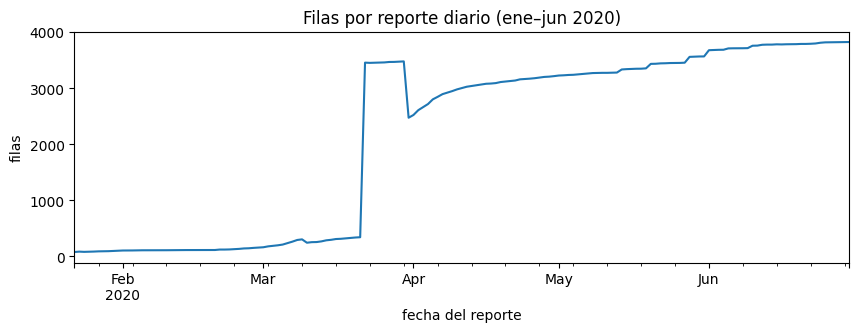

fecha_reporte
2020-03-20     335
2020-03-21     340
2020-03-22    3456
2020-03-23    3452
dtype: int64

In [11]:
# ¿Cuántas filas por día? El salto del 22-mar se debe a que EE.UU. empieza a reportar por condado
filas_dia = covid.groupby('fecha_reporte').size()
ax = filas_dia.plot(figsize=(10, 3), title='Filas por reporte diario (ene–jun 2020)')
ax.set_ylabel('filas'); ax.set_xlabel('fecha del reporte'); plt.show()
filas_dia.loc['2020-03-20':'2020-03-23']

## 6 · Top 10 países al 30-jun-2020 y evolución de Chile
Los valores son **acumulados**: el total de un país al 30-jun es la suma de sus filas (provincias, estados o condados) en el reporte de ese día. No se deben sumar días distintos.

In [12]:
corte = covid[covid['fecha_reporte'] == '2020-06-30']
top10 = (corte.groupby('country_region')[['confirmed', 'deaths']].sum()
              .sort_values('confirmed', ascending=False).head(10))
top10['letalidad_aparente_%'] = (top10['deaths'] / top10['confirmed'] * 100).round(2)
top10.style.format({'confirmed': '{:,.0f}', 'deaths': '{:,.0f}', 'letalidad_aparente_%': '{:.2f}'})

,confirmed,deaths,letalidad_aparente_%
country_region,,,
US,"2,653,658","127,095",4.79
Brazil,"1,412,669","59,792",4.23
Russia,"646,929","9,306",1.44
India,"585,493","17,400",2.97
United Kingdom,"314,157","56,284",17.92
Peru,"285,213","37,898",13.29
Chile,"279,393","5,688",2.04
Spain,"249,271","28,355",11.38
Italy,"240,578","34,767",14.45


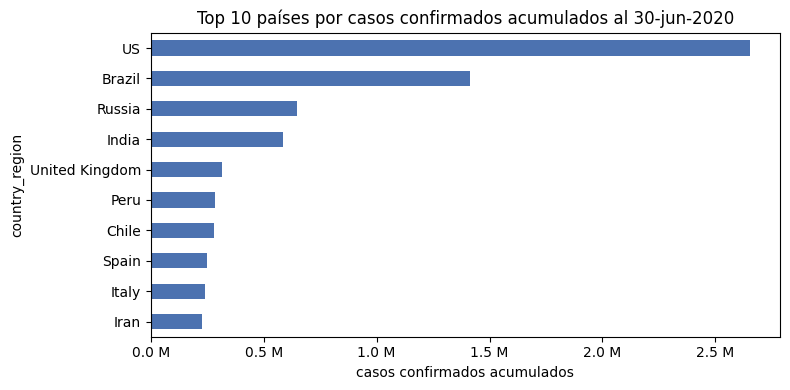

In [13]:
ax = top10['confirmed'].sort_values().plot.barh(figsize=(8, 4), color='#4C72B0')
ax.set_title('Top 10 países por casos confirmados acumulados al 30-jun-2020')
ax.set_xlabel('casos confirmados acumulados')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e6:.1f} M'))
plt.tight_layout(); plt.show()

In [14]:
chile = covid[covid['country_region'] == 'Chile']

# Ojo con la granularidad: Chile pasa de 1 fila (país) a 17 filas (16 regiones + 'Unknown')
gran = chile.groupby('fecha_reporte').size()
print('Filas por día de Chile:', gran.value_counts().to_dict())
print('Primer día con detalle regional:', gran[gran > 1].index.min().date())

# Sumando las filas de cada día se obtiene el total nacional en ambos períodos
chile_dia = chile.groupby('fecha_reporte')[['confirmed', 'deaths']].sum()
chile_dia['casos_nuevos'] = chile_dia['confirmed'].diff()          # nuevos = diferencia de acumulados
chile_dia['casos_nuevos_mm7'] = chile_dia['casos_nuevos'].rolling(7).mean()
chile_dia.tail()

Filas por día de Chile: {1: 78, 17: 42}
Primer día con detalle regional: 2020-05-20


,confirmed,deaths,casos_nuevos,casos_nuevos_mm7
fecha_reporte,,,,
2020-06-26,263360.0,5068.0,4296.0,4566.714286
2020-06-27,267766.0,5347.0,4406.0,4431.142857
2020-06-28,271982.0,5509.0,4216.0,4232.428571
2020-06-29,275999.0,5575.0,4017.0,4148.000000
2020-06-30,279393.0,5688.0,3394.0,4089.428571


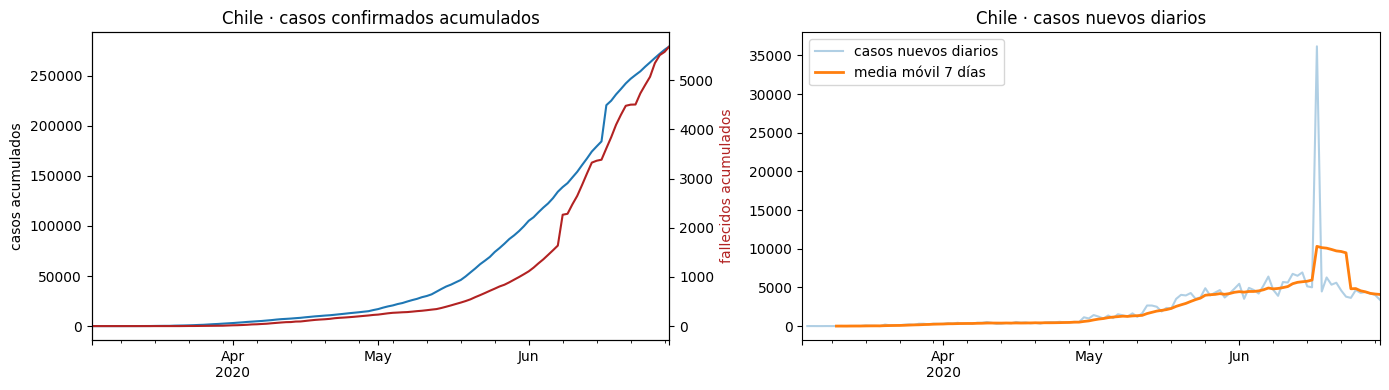

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
chile_dia.loc['2020-03-01':, ['confirmed']].plot(ax=axes[0], legend=False)
axes[0].set_title('Chile · casos confirmados acumulados'); axes[0].set_xlabel('')
ax2 = axes[0].twinx(); chile_dia.loc['2020-03-01':, 'deaths'].plot(ax=ax2, color='firebrick')
ax2.set_ylabel('fallecidos acumulados', color='firebrick'); axes[0].set_ylabel('casos acumulados')

chile_dia.loc['2020-03-01':, 'casos_nuevos'].plot(ax=axes[1], alpha=.35, label='casos nuevos diarios')
chile_dia.loc['2020-03-01':, 'casos_nuevos_mm7'].plot(ax=axes[1], lw=2, label='media móvil 7 días')
axes[1].set_title('Chile · casos nuevos diarios'); axes[1].legend(); axes[1].set_xlabel('')
plt.tight_layout(); plt.show()

In [16]:
# Días con casos nuevos negativos (el acumulado bajó por correcciones) -> se cuantifica en R2
print('Días con acumulado que baja en Chile:', (chile_dia['casos_nuevos'] < 0).sum())
chile_dia.loc[chile_dia['casos_nuevos'] < 0, ['confirmed', 'casos_nuevos']]

Días con acumulado que baja en Chile: 0


,confirmed,casos_nuevos
fecha_reporte,,


**Lectura de Chile (ene–jun 2020):**
* Primer caso el **3-mar-2020**; al 30-jun acumula **279.393 casos y 5.688 fallecidos**, 7.º del mundo en casos absolutos (detrás de EE.UU., Brasil, Rusia, India, Reino Unido y Perú).
* **Cambio de granularidad:** hasta el 19-may-2020 Chile es 1 fila (país); desde el **20-may-2020** son 17 filas (16 regiones + `Unknown`). Sumar las filas por día da el total nacional sin saltos, pero el DW deberá modelar esa jerarquía.
* **Pico artificial del 17-jun-2020:** el acumulado salta **+36.179 casos en un día** (los días vecinos rondan 5.000). No es un brote: es la carga de casos rezagados. La media móvil de 7 días «hereda» ese salto durante una semana (pasa de ~6.000 a ~10.300). Es exactamente el problema de *picos por acumulación de rezagos* que el componente R2 debe cuantificar y decidir si marcar o redistribuir.
* En este período Chile no tiene días con acumulado que baja; eso cambia en los tres años completos (lo mediremos en R2).

## 7 · Perfilado automático (ydata-profiling)
Se perfila la tabla unida ene–jun 2020 (~350 mil filas) con `minimal=True`; el HTML queda en `reports/`.

> **Nota técnica (conflicto de dependencias):** `ydata-profiling` exige NumPy < 2.4 (y usa `pkg_resources`, eliminado en setuptools ≥ 81), mientras Colab ya trae NumPy 2.4. Instalarlo en el mismo entorno obliga a reiniciar el runtime y rompe *Ejecutar todo*. Solución: se instala en una **carpeta aparte** (`pip --target`) y se ejecuta como subproceso sobre un Parquet de la tabla unida. El notebook no se ve afectado y el resultado es el mismo. La primera vez tarda ~1–2 min.

In [17]:
import subprocess, json
# ydata-profiling y sus dependencias (NumPy < 2.4, etc.) se instalan en una carpeta aparte.
# El subproceso la pone primero en PYTHONPATH; el kernel del notebook sigue usando sus propias versiones.
LIBS_PERFIL = Path('/tmp/libs_perfil')
ENV_SUB = {**os.environ, 'PYTHONPATH': str(LIBS_PERFIL),
           'MPLBACKEND': 'Agg'}          # el subproceso no puede usar el backend gráfico del notebook
if not (LIBS_PERFIL / 'ydata_profiling').exists():
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--target', str(LIBS_PERFIL),
                    'ydata-profiling', 'pyarrow', 'setuptools<81'],
                   check=True, capture_output=True)   # pip avisa de conflictos con el entorno de Colab: es esperable
print(subprocess.run([sys.executable, '-c', 'import ydata_profiling, numpy; print("ydata-profiling", ydata_profiling.__version__, "| numpy", numpy.__version__)'],
                     capture_output=True, text=True, check=True, env=ENV_SUB).stdout)

ydata-profiling 4.18.4 | numpy 2.3.5



In [18]:
ENTRADA = Path('/tmp/covid_ene_jun_2020.parquet')
SALIDA_HTML = REPORTS_DIR / 'perfil_ene_jun_2020.html'
SALIDA_JSON = Path('/tmp/perfil_resumen.json')
covid.drop(columns=['archivo_origen']).to_parquet(ENTRADA, index=False)

SCRIPT = """
import sys, json, warnings
warnings.filterwarnings('ignore')
import pandas as pd
from ydata_profiling import ProfileReport
df = pd.read_parquet(sys.argv[1])
perfil = ProfileReport(df, title='Perfil - Reportes diarios JHU ene-jun 2020', minimal=True, progress_bar=False)
perfil.to_file(sys.argv[2])
d = perfil.get_description()
json.dump({
    'n': int(d.table['n']), 'p_cells_missing': float(d.table['p_cells_missing']),
    'variables': {k: {'tipo': str(v['type']), 'p_missing': float(v['p_missing']), 'n_distinct': int(v.get('n_distinct', 0))}
                  for k, v in d.variables.items()},
    'alertas': [str(a) for a in d.alerts]}, open(sys.argv[3], 'w'), ensure_ascii=False)
"""
r = subprocess.run([sys.executable, '-c', SCRIPT, str(ENTRADA), str(SALIDA_HTML), str(SALIDA_JSON)], capture_output=True, text=True, env=ENV_SUB)
assert r.returncode == 0, r.stderr[-3000:]
print('Perfil guardado en', SALIDA_HTML, '(en Colab: panel Archivos -> descargar)')

Perfil guardado en /home/claude/facuna-m/proyecto-gestion-datos-2026/reports/perfil_ene_jun_2020.html (en Colab: panel Archivos -> descargar)


In [19]:
# Cifras clave del perfil, para respaldar las observaciones
desc = json.load(open(SALIDA_JSON))
resumen = pd.DataFrame({k: {'tipo': v['tipo'], '%_faltantes': round(v['p_missing'] * 100, 1), 'distintos': v['n_distinct']}
                        for k, v in desc['variables'].items()}).T
print('Filas:', desc['n'], '| celdas faltantes: %.1f %%' % (desc['p_cells_missing'] * 100))
print('Filas duplicadas exactas:', covid.drop(columns=['archivo_origen']).duplicated().sum())
llave = ['fecha_reporte', 'country_region', 'province_state', 'admin2']
print('Filas duplicadas en la llave territorio x día:', covid.duplicated(subset=llave).sum())
print('\nAlertas del perfil:')
for a in desc['alertas']:
    print(' -', a)
resumen

Filas: 350945 | celdas faltantes: 12.0 %


Filas duplicadas exactas: 1
Filas duplicadas en la llave territorio x día: 3

Alertas del perfil:
 - [province_state] 22249 (6.3%) missing values
 - [lat] 10694 (3.0%) missing values
 - [long] 10694 (3.0%) missing values
 - [fips] 55107 (15.7%) missing values
 - [admin2] 54721 (15.6%) missing values
 - [active] 9797 (2.8%) missing values
 - [combined_key] 9797 (2.8%) missing values
 - [incidence_rate] 229813 (65.5%) missing values
 - [case_fatality_ratio] 229467 (65.4%) missing values
 - [deaths] is highly skewed(γ1 = 28.230195612440106)
 - [recovered] is highly skewed(γ1 = 44.82840775678202)
 - [active] is highly skewed(γ1 = 20.320789981815178)
 - [case_fatality_ratio] is highly skewed(γ1 = 153.80639083534348)
 - [confirmed] has 25157 (7.2%) zeros
 - [deaths] has 169079 (48.2%) zeros
 - [recovered] has 310654 (88.5%) zeros
 - [active] has 26330 (7.5%) zeros
 - [case_fatality_ratio] has 41133 (11.7%) zeros


,tipo,%_faltantes,distintos
fecha_reporte,DateTime,0.0,161
province_state,Text,6.3,730
country_region,Text,0.0,246
last_update,DateTime,0.0,163
confirmed,Numeric,0.0,15173
deaths,Numeric,0.1,3806
recovered,Numeric,0.1,7853
lat,Numeric,3.0,4276
long,Numeric,3.0,4306
fips,Numeric,15.7,3217


In [20]:
# Comprobaciones que respaldan las observaciones
print('Valores negativos en active:', (covid['active'] < 0).sum())
print('Filas con lat = long = 0:', ((covid['lat'] == 0) & (covid['long'] == 0)).sum())
print('Filas con todos los conteos en 0:',
      (covid[['confirmed', 'deaths', 'recovered']].fillna(0).sum(axis=1) == 0).sum())
print('Nombres de país distintos:', covid['country_region'].nunique())
alias = ['Mainland China', 'China', 'Korea, South', 'South Korea', 'Republic of Korea',
         'Iran', 'Iran (Islamic Republic of)', 'Taiwan', 'Taiwan*', 'Czech Republic', 'Czechia']
covid[covid['country_region'].isin(alias)].groupby('country_region')['fecha_reporte'].agg(['min', 'max', 'count'])

Valores negativos en active: 0
Filas con lat = long = 0: 370
Filas con todos los conteos en 0: 23690
Nombres de país distintos: 246


,min,max,count
country_region,,,
China,2020-01-22,2020-06-30,3857
Czech Republic,2020-03-01,2020-03-10,10
Czechia,2020-03-11,2020-06-30,112
Iran,2020-02-19,2020-06-30,132
Iran (Islamic Republic of),2020-03-10,2020-03-10,1
"Korea, South",2020-03-11,2020-06-30,112
Mainland China,2020-01-22,2020-03-12,1517
Republic of Korea,2020-03-10,2020-03-10,1
South Korea,2020-01-22,2020-03-09,48


### Tres observaciones del perfilado
1. **Los nulos son estructurales, no errores de captura.** `incidence_rate` y `case_fatality_ratio` faltan en el **65 %** de las filas, y `fips`/`admin2` en el **16 %**: no es que falten datos, es que esas columnas **no existían** antes del 29-may y del 22-mar respectivamente, o solo aplican a EE.UU. El porcentaje de nulos de la tabla unida mide los *cambios de esquema*, no la calidad del dato. En el diccionario (R2) cada columna llevará su «desde qué fecha existe».
2. **Mucho cero y fuerte asimetría.** `deaths` tiene **48 % de ceros**, `recovered` **88 %**, y el perfil marca asimetría extrema (γ1 ≈ 28 en fallecidos). Además hay **23.690 filas con todos los conteos en 0**, incluidas entidades que no existían en enero de 2020 (*Summer Olympics 2020*, *Winter Olympics 2022*, *Antarctica*): JHU las agregó **retroactivamente** a los archivos antiguos. Consecuencia: los promedios simples no sirven; usaremos medianas, tasas por 100.000 y escalas logarítmicas.
3. **El mismo país aparece con varios nombres y hay duplicados.** Hay **246 nombres de país** distintos en solo seis meses: *Mainland China*/*China*, *South Korea*/*Republic of Korea*/*Korea, South*, `Taiwan`/`Taiwan*`, *Czech Republic*/*Czechia*, *Iran*/*Iran (Islamic Republic of)*. Además hay **3 filas duplicadas** en la llave territorio × día (Hubei el 23-ene, Nueva Zelanda el 26-feb y un condado de EE.UU. el 22-mar con **fallecidos distintos**: 0 vs 2). La llave del DW no puede ser el nombre: hay que homologar con la tabla UID (código ISO3) y definir una regla de deduplicación (R2 · unicidad y consistencia). También hay **370 filas con lat = long = 0** (coordenadas falsas en el golfo de Guinea) que no pueden ir al mapa.

## 8 · Conclusiones para las siguientes etapas
* La **unificación de esquemas** ya funciona para 4 de las 5 etapas con snake_case + un mapa de renombres; la 5.ª (`incident_rate`, `case_fatality_ratio`, desde 9-nov-2020) se resuelve en `01_ingesta`.
* Necesitamos una **tabla de homologación de países** (o, mejor, usar la tabla UID/ISO3) antes de agrupar por país en los tres años.
* La fecha oficial de cada fila será `fecha_reporte` (del nombre del archivo); `last_update` solo informa la hora de actualización.
* Los acumulados que bajan y los cambios de granularidad (Chile, EE.UU.) son el material del componente R2 (calidad).